=== WIKIPEDIA: DESCRIPTIVE STATISTICS ===
Total Articles Scraped: 35
Valid Articles Analyzed: 35
Missing/Failed Data Rate: 0.00%



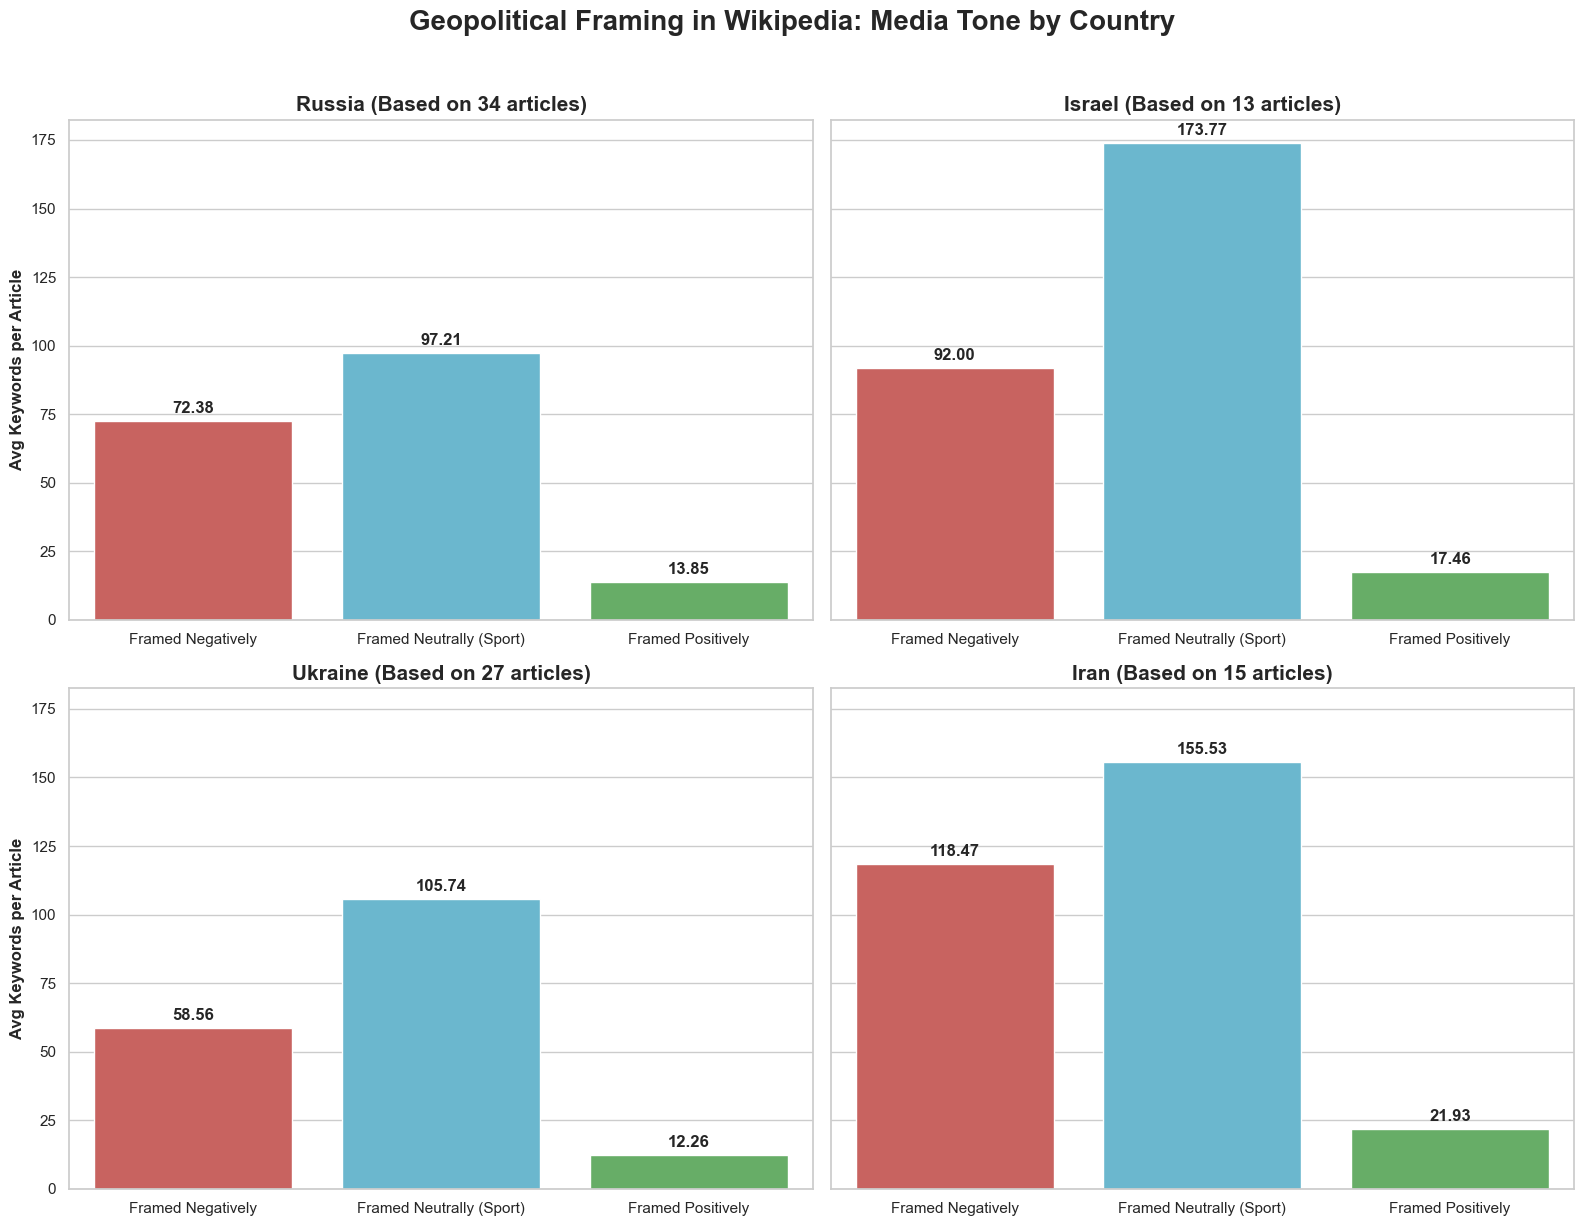

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json

# 1. Keyword Buckets
framing_buckets = {
    "Framed Negatively": [
        "sanction", "sanctions", "ban", "banned", "war", "conflict", "invasion",
        "tension", "geopolitical", "controversy", "controversial", "protest", 
        "boycott", "violation", "dispute", "restriction", "suspension", 
        "propaganda", "crisis", "disqualification", "disqualified", "aggression", 
        "condemn", "bad", "terrible", "threat", "hostile", "escalate", 
        "escalation", "authoritarian", "regime", "unprovoked", "breach", 
        "atrocity", "unlawful", "illicit", "retaliation", "punitive", 
        "isolation", "isolated", "exclusion", "excluded", "doping", 
        "scandal", "corruption", "dissent", "alienation"
    ],
    "Framed Neutrally (Sport)": [
        "athlete", "athletes", "competition", "compete", "competing",
        "performance", "perform", "medal", "gold", "silver", "bronze",
        "event", "race", "match", "training", "coach", "qualification",
        "qualify", "team", "score", "result", "season", "final", "win", 
        "victory", "championship", "tournament", "standings", "podium"
    ],
    "Framed Positively": [
        "success", "successful", "hope", "hopeful", "peace", "unity", 
        "triumph", "support", "resilience", "overcome", "proud", 
        "solidarity", "celebration", "courage", "inspiring", "fairness",
        "diplomatic", "diplomacy", "truce", "reconciliation", "integration", 
        "welcome", "welcomed", "achievement", "perseverance", "harmony", 
        "cooperation", "goodwill", "heroic", "historic", "breakthrough", 
        "fair play", "sportsmanship", "camaraderie"
    ]
}

country_keywords = {
    "Russia": ["russia", "russian", "moscow", "ain", "neutral athlete"],
    "Israel": ["israel", "israeli", "tel aviv"],
    "Ukraine": ["ukraine", "ukrainian", "kyiv"],
    "Iran": ["iran", "iranian", "tehran"]
}

# 2. Load the Wikipedia Data
try:
    with open('Wiki_Articles.json', 'r', encoding='utf-8') as f:
        wiki_data = json.load(f)
except FileNotFoundError:
    print("Error: Could not find 'Wiki_Articles.json'.")
    wiki_data = []

# 3. Print Descriptive Statistics & Data Health
total_urls = len(wiki_data)
valid_articles = sum(1 for article in wiki_data if len(article.get("Article_Text", "")) > 50)
missing_rate = ((total_urls - valid_articles) / total_urls) * 100 if total_urls > 0 else 0

print("=== WIKIPEDIA: DESCRIPTIVE STATISTICS ===")
print(f"Total Articles Scraped: {total_urls}")
print(f"Valid Articles Analyzed: {valid_articles}")
print(f"Missing/Failed Data Rate: {missing_rate:.2f}%\n")

# 4. Setup tracking dictionaries
wiki_stats = {country: {"Article_Count": 0, "Frames": {frame: 0 for frame in framing_buckets}} for country in country_keywords}

# 5. Sort and Analyze the Articles
for article in wiki_data:
    text = article.get("Article_Text", "").lower()
    
    for country, keywords in country_keywords.items():
        if any(kw in text for kw in keywords):
            wiki_stats[country]["Article_Count"] += 1
            for frame_name, frame_words in framing_buckets.items():
                for word in frame_words:
                    wiki_stats[country]["Frames"][frame_name] += text.count(word.lower())

# 6. Calculate Averages
plot_data = []
for country, data in wiki_stats.items():
    count = data["Article_Count"]
    if count > 0:
        for frame, total in data["Frames"].items():
            plot_data.append({"Country": country, "Framing Type": frame, "Average Mentions": total / count})
    else:
        for frame in framing_buckets:
             plot_data.append({"Country": country, "Framing Type": frame, "Average Mentions": 0.0})

df_wiki_plot = pd.DataFrame(plot_data)

# 7. Generate the 2x2 Grid
sns.set_theme(style="whitegrid")
custom_colors = ["#d9534f", "#5bc0de", "#5cb85c"] 

fig, axes = plt.subplots(2, 2, figsize=(16, 12), sharey=True)
fig.suptitle('Geopolitical Framing in Wikipedia: Media Tone by Country', fontsize=20, fontweight='bold', y=1.02)
axes = axes.flatten()

countries = list(country_keywords.keys())

for i, country in enumerate(countries):
    country_data = df_wiki_plot[df_wiki_plot["Country"] == country]
    ax = sns.barplot(data=country_data, x="Framing Type", y="Average Mentions", hue="Framing Type", palette=custom_colors, legend=False, ax=axes[i])
    
    article_count = wiki_stats[country]["Article_Count"]
    axes[i].set_title(f'{country} (Based on {article_count} articles)', fontsize=15, fontweight='bold')
    axes[i].set_xlabel('')
    
    if i % 2 == 0: 
        axes[i].set_ylabel('Avg Keywords per Article', fontsize=12, fontweight='bold')
    else:
        axes[i].set_ylabel('')
        
    for p in ax.patches:
        height = p.get_height()
        if height > 0: 
            ax.annotate(f'{height:.2f}', 
                        (p.get_x() + p.get_width() / 2., height), 
                        ha='center', va='center', xytext=(0, 9), textcoords='offset points', fontweight='bold')

plt.tight_layout()
plt.show()

### Wikipedia: Preliminary Observations & Anomalies

* **Observation:** Wikipedia articles feature a massive keyword count per page because they are so long and encyclopedic. However, despite the sheer length of these pages, neutral sports terms are still the most common category. This shows Wikipedia maintains a factual focus on the athletic events themselves rather than just the controversies.
* **Anomaly:** The countries with the fewest articles (Iran and Israel) have a surprisingly high rate of negative words per article (averaging 118.47 and 92.00). This shows that their limited presence on these Wikipedia pages is heavily tied to political conflict rather than just athletic participation.